# 05 RQ2 Regime Classification

Synopsis RQ2: news / GDELT risk features vs no-text baseline for volatility regime.

Optional FinBERT: replace `finbert_risk_probability` after installing torch+transformers.


In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from project_paths import load_env, ensure_output_dirs
ROOT = load_env()
PATHS = ensure_output_dirs(ROOT)
print("ROOT", ROOT)
print({k: str(v) for k, v in PATHS.items()})

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, accuracy_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid", context="talk")
df = pd.read_csv(PATHS["processed"] / "daily_panel_clean.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
print(df.shape)


ROOT /Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold
{'root': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold', 'raw': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/raw', 'processed': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/data/processed', 'outputs': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest', 'figures': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/figures', 'tables': '/Users/govind/Documents/govind/DBA/QM_640_Analytics_Capstone/github_scaffold/notebooks/outputs/latest/tables'}


(2066, 23)


In [2]:
text_features = [c for c in ["news_event_impact_score","finbert_risk_probability","gdelt_article_volume"] if c in df.columns]
market_features = [c for c in ["wti_spot","commodity_roll_yield","natgas_hh"] if c in df.columns]
work = df.dropna(subset=market_features + ["volatility_regime"]).copy()
split = int(len(work) * 0.7)
train, test = work.iloc[:split], work.iloc[split:]

def eval_clf(name, feats):
    feats = [f for f in feats if f in work.columns]
    tr = train.dropna(subset=feats)
    te = test.dropna(subset=feats)
    Xtr, ytr = tr[feats], tr["volatility_regime"].astype(int)
    Xte, yte = te[feats], te["volatility_regime"].astype(int)
    if ytr.nunique() < 2 or yte.nunique() < 2:
        return {"Model": name, "Feature Set": ",".join(feats), "Validation Approach": "chronological 70/30", "Accuracy": np.nan, "F1": np.nan, "AUC": np.nan, "Key Takeaway": "Need both classes in split"}
    clf = GradientBoostingClassifier(random_state=42)
    clf.fit(Xtr, ytr)
    prob = clf.predict_proba(Xte)[:, 1]
    pred = clf.predict(Xte)
    return {
        "Model": name,
        "Feature Set": ",".join(feats),
        "Validation Approach": "chronological 70/30",
        "Accuracy": accuracy_score(yte, pred),
        "F1": f1_score(yte, pred, zero_division=0),
        "AUC": roc_auc_score(yte, prob) if yte.nunique() > 1 else np.nan,
        "Key Takeaway": "",
        "_yte": yte, "_prob": prob, "_pred": pred, "_clf": clf,
    }

base = eval_clf("no_text_market_baseline", market_features)
full = eval_clf("market_plus_news", market_features + text_features)
metrics = pd.DataFrame([{k:v for k,v in r.items() if not k.startswith("_")} for r in [base, full]])
if metrics["F1"].notna().any():
    winner = metrics.sort_values("F1", ascending=False).iloc[0]["Model"]
    metrics.loc[metrics["Model"]==winner, "Key Takeaway"] = "Higher F1 on holdout"
metrics.to_csv(PATHS["outputs"] / "metrics_rq2.csv", index=False)
metrics.to_csv(PATHS["tables"] / "model_performance_rq2.csv", index=False)
metrics


,Model,Feature Set,Validation Approach,Accuracy,F1,AUC,Key Takeaway
0,no_text_market_baseline,"wti_spot,commodity_roll_yield,natgas_hh",chronological 70/30,0.551220,0.591716,0.616127,Higher F1 on holdout
1,market_plus_news,"wti_spot,commodity_roll_yield,natgas_hh,news_e...",chronological 70/30,0.546667,0.413793,0.515855,


### Figure 5. RQ2 ROC and confusion (news-enhanced model when available)


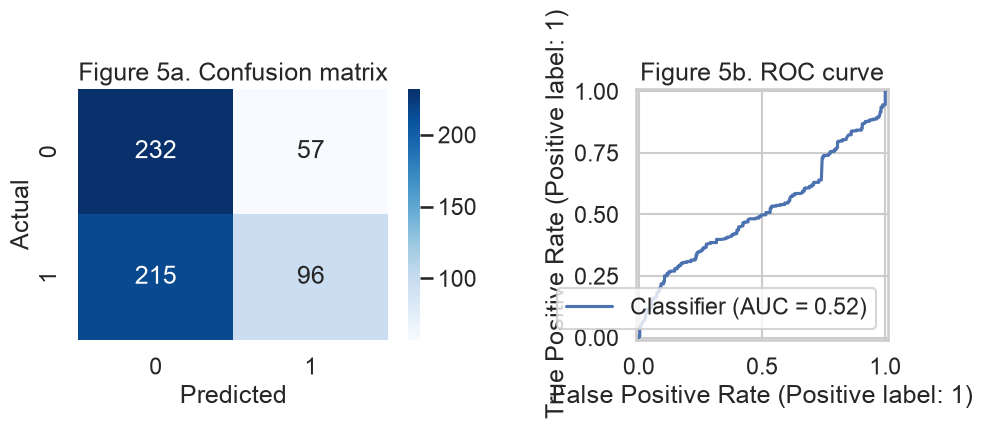

,Model,Feature Set,Validation Approach,Accuracy,F1,AUC,Key Takeaway
0,no_text_market_baseline,"wti_spot,commodity_roll_yield,natgas_hh",chronological 70/30,0.551220,0.591716,0.616127,Higher F1 on holdout
1,market_plus_news,"wti_spot,commodity_roll_yield,natgas_hh,news_e...",chronological 70/30,0.546667,0.413793,0.515855,


In [3]:
chosen = full if full.get("_pred") is not None else base
if chosen.get("_pred") is not None:
    yte, pred, prob = chosen["_yte"], chosen["_pred"], chosen["_prob"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    cm = confusion_matrix(yte, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("Figure 5a. Confusion matrix")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    RocCurveDisplay.from_predictions(yte, prob, ax=axes[1])
    axes[1].set_title("Figure 5b. ROC curve")
    fig.tight_layout()
    fig.savefig(PATHS["figures"] / "fig05_rq2_roc_cm.png", dpi=200)
    plt.show()
else:
    print("Insufficient class balance for ROC/CM in this split")
metrics
